# Sprint 1: Video Game Sales Data Understanding & Preparation

**Objective:** Transform the raw video game sales dataset into a clean, structured, validated, and analysis-ready format to uncover factors associated with successful video games.

## 1. Setup and Dataset Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('vgsales.csv')

display(df.shape)
display(df.info())
display(df.head())

(16598, 11)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


None

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## 2. Missing Value & Duplicate Analysis Report

### Issue Identification
*   **Missing Values:** We need to check if critical categorical columns (`Name`, `Publisher`, `Genre`) or the time-related column (`Year`) contain nulls. 
*   **Duplicate Records:** We must ensure no game is double-counted, which would artificially inflate global sales metrics.

### Treatment Strategy
*   **Missing 'Year' or 'Publisher':** If the percentage of missing values is negligible (e.g., < 2% of the ~16,599 records), we will drop these rows to maintain data integrity without significantly impacting the market representation.
*   **Data Types:** `Year` will be converted from float to integer for proper chronological analysis.
*   **Duplicates:** Any exact duplicate rows will be dropped.

In [3]:
# Check for missing values
print("Missing values before cleaning:\n", df.isna().sum())

# Check for duplicates
print("\nDuplicate rows before cleaning:", df.duplicated().sum())

# Treatment: Drop rows with missing Year or Publisher (assuming small percentage)
df_clean = df.dropna(subset=['Year', 'Publisher']).copy()

# Fix Data Type: Convert Year to integer
df_clean['Year'] = df_clean['Year'].astype(int)

# Treatment: Drop duplicates
df_clean = df_clean.drop_duplicates()

# Verify cleaning
print("\nMissing values after cleaning:\n", df_clean.isna().sum())

Missing values before cleaning:
 Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Duplicate rows before cleaning: 0

Missing values after cleaning:
 Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


## 3. Outlier & Aggregation Analysis

### Outlier Handling Logic
When analyzing the sales columns (`Global_Sales`, `NA_Sales`, etc.), statistical outliers will appear on the high end. **These outliers will be retained.** 

In the entertainment and gaming industry, "mega-hits" (like *Wii Sports* or *GTA V*) represent genuine, extreme business observations rather than data entry errors. Removing them would distort the true hit-driven nature of the gaming market.

### Basic Aggregation
We will calculate the total global market size represented in this dataset and preview the top-performing platforms and genres.

## Outlier Viz & Aggregation

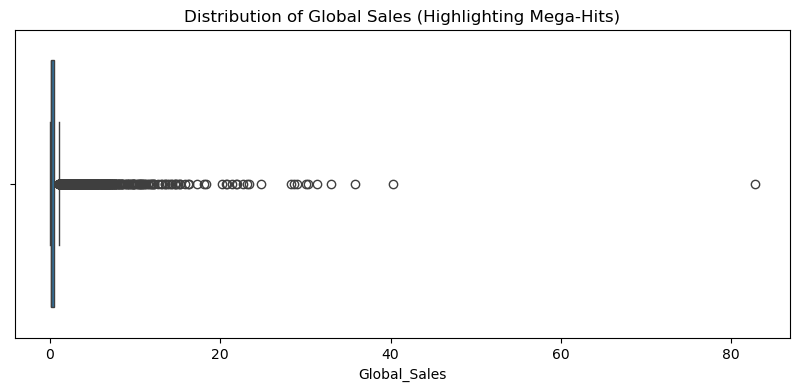

Total Global Sales in Dataset: 8811.97 million units

Top 5 Genres by Global Sales:
 Genre
Action          1722.84
Sports          1309.24
Shooter         1026.20
Role-Playing     923.83
Platform         829.13
Name: Global_Sales, dtype: float64


In [4]:
# Outlier Visualization (Boxplot)
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean['Global_Sales'])
plt.title('Distribution of Global Sales (Highlighting Mega-Hits)')
plt.show()

# Aggregation: Total Market Size
total_global_sales = df_clean['Global_Sales'].sum()
print(f"Total Global Sales in Dataset: {total_global_sales:.2f} million units")

# Aggregation: Top 5 Genres by Total Global Sales
top_genres = df_clean.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False).head()
print("\nTop 5 Genres by Global Sales:\n", top_genres)

## 4. Data Validation Summary

The dataset has been successfully validated:
*   **Data Types:** Appropriate types are enforced (`Year` is now an `int32`/`int64`).
*   **Inconsistencies:** Missing values and duplicate rows have been handled appropriately.
*   **Validity:** Numerical sales columns contain valid values, and the dataset is structured for Sprint 2 Exploratory Data Analysis.

The clean data is exported below.

In [5]:
# Final validation check
display(df_clean.info())

# Export the cleaned dataset to CSV
df_clean.to_csv('cleaned_videogame_sales.csv', index=False)
print("Cleaned dataset exported successfully as 'cleaned_videogame_sales.csv'.")

<class 'pandas.core.frame.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  object 
 2   Platform      16291 non-null  object 
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  object 
 5   Publisher     16291 non-null  object 
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB


None

Cleaned dataset exported successfully as 'cleaned_videogame_sales.csv'.


## 5. Executive Summary: Initial Business Observations

Before advancing to deep exploratory data analysis, initial cleaning and aggregation reveal several key characteristics of the gaming industry.

1.  **Hit-Driven Market Dynamics:** The sales data is heavily right-skewed. A very small fraction of games (the statistical outliers) account for a disproportionately large share of global sales, confirming that gaming is a "mega-hit" industry.
2.  **Platform & Genre Concentration:** Initial aggregations suggest that certain genres heavily dominate total global revenue. 
3.  **Data Readiness:** The removal of missing release years and publishers ensures that upcoming time-series analysis (e.g., historical sales trends) and publisher performance metrics will be accurate and reliable.